# 08. Member 4 — LightGBM Development and Formal-Workflow Report

## 1. Objective and evaluation boundary

LightGBM is Member 4's headline model. This notebook preserves the completed pre-harmonization experiment as **HISTORICAL / PRE-HARMONIZATION EVIDENCE** and reports the completed formal strict-nested development evaluation. The historical globally selected C08 result is not the formal headline estimate.

Historical LGBM_C01–LGBM_C08 candidates were previously evaluated with the shared run_5fold_cv workflow and selected globally by pooled OOF Average Precision. They remain unchanged as development evidence. The approved formal registry is LGBM_F01–LGBM_F08, selected independently inside every outer-training fold. The formal 20,000-row holdout remains untouched.

## 2. Reproducibility, paths, and imports

All paths are resolved relative to the repository root. Historical metrics and OOF integrity are checked with shared utilities. The one completed formal run is documented below from saved strict_nested artifacts. Its expensive execution guard remains disabled by default.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
from sklearn.metrics import precision_recall_curve

def find_project_root(start_path: Path | None = None) -> Path:
    """Locate the repository root from any notebook launch directory."""
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.evaluation.oof_validation import validate_oof_predictions
from src.models.config import load_model_config
from src.models.lightgbm_execution import load_lightgbm_development_only, write_lightgbm_formal_artifacts
from src.models.lightgbm_model import LightGBMAdapter
from src.models.runner import run_5fold_cv

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1200)

RESULTS_DIR = PROJECT_ROOT / 'results' / 'models' / 'lightgbm'
SPLIT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'split_registry.csv'
FEATURE_CONTRACT_PATH = PROJECT_ROOT / 'configs' / 'feature_contract.yaml'
SPLIT_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'split_config.yaml'
MODEL_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'models' / 'lightgbm.yaml'
FINAL_OOF_PATH = RESULTS_DIR / 'lightgbm_final_oof_predictions.csv'
FINAL_FOLD_PATH = RESULTS_DIR / 'lightgbm_final_fold_metrics.csv'
FINAL_SUMMARY_PATH = RESULTS_DIR / 'lightgbm_final_summary_metrics.json'
SELECTED_CONFIG_PATH = RESULTS_DIR / 'lightgbm_selected_config.json'
CANDIDATE_COMPARISON_PATH = RESULTS_DIR / 'lightgbm_candidate_comparison.csv'
THRESHOLD_PATH = RESULTS_DIR / 'threshold_analysis.csv'
THRESHOLD_METADATA_PATH = RESULTS_DIR / 'lightgbm_development_threshold.json'
FINAL_IMPORTANCE_PATH = RESULTS_DIR / 'lightgbm_final_feature_importances.csv'
FINAL_IMPORTANCE_FIGURE = RESULTS_DIR / 'figure_02_lightgbm_selected_feature_importance.png'
PROBABILITY_FIGURE = RESULTS_DIR / 'figure_03_lightgbm_oof_probability_distribution.png'
PR_FIGURE = RESULTS_DIR / 'figure_04_lightgbm_precision_recall_curve.png'

print(f'Project root: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')
print(f'LightGBM: {lightgbm.__version__}')
print('Execution mode: historical artifact validation; formal strict-nested training guard disabled')

Project root: C:\Users\HP\Desktop\SLIIT\2Y1S\AIML\Project
Python: 3.14.7
LightGBM: 4.7.0
Execution mode: saved-artifact validation and reporting only (no training)


## FORMAL STRICT-NESTED LIGHTGBM EVALUATION — completed once

The approved LGBM_F01–LGBM_F08 registry was evaluated independently inside each frozen outer-training fold. All candidates in a fold shared one stratified 15% inner split. Inner Average Precision selected the winner, exact ties used candidate ID ascending, and the selected best iteration was used for a no-validation refit on all outer-training rows. The untouched outer fold was prediction-only. The formal loader read raw Employee_ID values first, then parsed only development-row predictors and target; holdout feature and target values were never loaded. One completed run produced 40 candidate evaluations, 5 winner refits, and 80,000 strict-nested OOF predictions under results/models/lightgbm/strict_nested/. The expensive run guard remains disabled by default.

In [ ]:
RUN_FORMAL_STRICT_NESTED_CV = False
FORMAL_RESULTS_DIR = RESULTS_DIR / 'strict_nested'

if RUN_FORMAL_STRICT_NESTED_CV:
    formal_config = load_model_config(MODEL_CONFIG_PATH, strict_schema=True)
    formal_candidate_ids = [item['id'] for item in formal_config['candidates']]
    assert formal_candidate_ids == [f'LGBM_F{i:02d}' for i in range(1, 9)]

    with FEATURE_CONTRACT_PATH.open('r', encoding='utf-8') as handle:
        formal_feature_contract = yaml.safe_load(handle)
    formal_features = formal_feature_contract['primary_model_features']
    raw_path = PROJECT_ROOT / 'data' / 'raw' / 'Extended_Employee_Performance_and_Productivity_Data.csv'
    formal_registry = pd.read_csv(SPLIT_PATH, dtype={'cv_fold': 'Int64'})
    formal_development = load_lightgbm_development_only(raw_path, formal_registry, formal_features)
    formal_dev_ids = set(formal_registry.loc[formal_registry['partition'] == 'development', 'Employee_ID'])
    formal_holdout_ids = set(formal_registry.loc[formal_registry['partition'] == 'holdout', 'Employee_ID'])
    assert len(formal_development) == 80_000
    assert set(formal_development['Employee_ID']) == formal_dev_ids
    assert not set(formal_development['Employee_ID']) & formal_holdout_ids
    assert len(formal_features) == 17 and set(formal_features).issubset(formal_development.columns)
    print(f'Development-only shape after row-selective CSV loading: {formal_development.shape}')
    display(formal_development['Resigned'].value_counts(dropna=False).rename('count').to_frame())
    display(formal_development['Resigned'].value_counts(normalize=True, dropna=False).rename('proportion').to_frame())

    fitted_outer_adapters = []
    def make_formal_lightgbm_adapter():
        outer_fold = len(fitted_outer_adapters) + 1
        adapter = LightGBMAdapter(config=formal_config, candidate_id='auto', outer_fold=outer_fold)
        fitted_outer_adapters.append(adapter)
        return adapter

    formal_result = run_5fold_cv(
        adapter_factory=make_formal_lightgbm_adapter,
        data=formal_development,
        split_registry=formal_registry,
        feature_cols=formal_features,
        target_col='Resigned',
        expected_model_name='LightGBM',
    )
    assert len(fitted_outer_adapters) == 5
    assert len(formal_result.predictions) == 80_000
    assert formal_result.predictions['Employee_ID'].nunique() == 80_000
    for adapter in fitted_outer_adapters:
        metadata = adapter.get_metadata()
        assert len(metadata['candidate_selection_records']) == 8
        assert metadata['fit_summary']['outer_training_row_count'] == 64_000
        assert metadata['fit_summary']['inner_training_row_count'] == 54_400
        assert metadata['fit_summary']['inner_validation_row_count'] == 9_600
    formal_source_head = subprocess.run(
        ['git', 'rev-parse', 'HEAD'], cwd=PROJECT_ROOT, check=True, capture_output=True, text=True
    ).stdout.strip()
    formal_outputs = write_lightgbm_formal_artifacts(
        result=formal_result, adapters=fitted_outer_adapters,
        development=formal_development, split_registry=formal_registry,
        config=formal_config, project_root=PROJECT_ROOT,
        output_dir=FORMAL_RESULTS_DIR, source_head=formal_source_head,
    )
    display(formal_outputs['fold_selection'])
    display(pd.Series(formal_outputs['summary_metrics'], name='FORMAL STRICT-NESTED LIGHTGBM'))
    print('Formal strict-nested artifacts validated and saved to', FORMAL_RESULTS_DIR)
else:
    print('RUN_FORMAL_STRICT_NESTED_CV is False: no formal LightGBM models were trained.')

## Formal strict-nested results from the completed development run

The saved artifacts under results/models/lightgbm/strict_nested/ are the source for this report. One formal run evaluated all **LGBM_F01–LGBM_F08** candidates within each of five frozen outer-training folds: **40/40 candidate evaluations succeeded**, **5/5 fold winners were refitted**, and **80,000/80,000 development employees received one OOF probability** (16,000 per fold). Development-ID parity and target/fold membership were validated against the frozen registry. Formal-holdout overlap was **0**; holdout predictors and targets were not loaded. Wall time was **82.53 seconds**. The saved execution guard above remains False to prevent another training run.

| Outer fold | Selected candidate | Inner AP | Best iteration | Class weight | Outer-fold AP | Fold runtime (s) |
|---:|---|---:|---:|---|---:|---:|
| 1 | LGBM_F07 | 0.109703 | 17 | null | 0.102428 | 10.41 |
| 2 | LGBM_F06 | 0.110341 | 10 | balanced | 0.100170 | 12.89 |
| 3 | LGBM_F02 | 0.107346 | 253 | balanced | 0.101850 | 19.24 |
| 4 | LGBM_F06 | 0.106122 | 3 | balanced | 0.100389 | 11.17 |
| 5 | LGBM_F07 | 0.105562 | 27 | null | 0.096173 | 14.65 |

**Pooled formal OOF metrics, threshold 0.50 where applicable:** Average Precision / PR-AUC **0.1001532612**; ROC-AUC **0.4987401319**; precision **0.0991895203**; recall **0.2628621379**; F1 **0.1440301061**; balanced accuracy **0.4986593721**; Brier score **0.1802153598**. Confusion counts: TN **52,875**, FP **19,117**, FN **5,903**, TP **2,105**. Mean fold AP **0.1002019815**, standard deviation **0.0024461891**. These values come from the new strict-nested OOF file, not the historical globally selected C08 output.

**Formal artifact paths:** results/models/lightgbm/strict_nested/oof_predictions.csv, fold_metrics.csv, summary_metrics.json, fold_selection.csv, candidate_selection.csv, runtime_efficiency.csv, run_metadata.json, and output_manifest.csv (the latter seven names share the same directory). The metadata records source HEAD e86b030d4eba9c91a170db623fdff67bfa7af089 and fold-specific winners. The historical LGBM_C01–LGBM_C08 and globally selected C08 outputs below remain **HISTORICAL / PRE-HARMONIZATION EVIDENCE**, not one universal formal selected candidate.

In [ ]:
formal_saved_oof = pd.read_csv(FORMAL_RESULTS_DIR / 'oof_predictions.csv')
formal_saved_folds = pd.read_csv(FORMAL_RESULTS_DIR / 'fold_selection.csv')
formal_saved_candidates = pd.read_csv(FORMAL_RESULTS_DIR / 'candidate_selection.csv')
formal_saved_fold_metrics = pd.read_csv(FORMAL_RESULTS_DIR / 'fold_metrics.csv')
formal_saved_manifest = pd.read_csv(FORMAL_RESULTS_DIR / 'output_manifest.csv')
with (FORMAL_RESULTS_DIR / 'summary_metrics.json').open('r', encoding='utf-8') as handle:
    formal_saved_summary = json.load(handle)
with (FORMAL_RESULTS_DIR / 'run_metadata.json').open('r', encoding='utf-8') as handle:
    formal_saved_metadata = json.load(handle)
formal_saved_registry = pd.read_csv(SPLIT_PATH, dtype={'cv_fold': 'Int64'})
validate_oof_predictions(formal_saved_oof, formal_saved_registry, expected_model_name='LightGBM')
assert len(formal_saved_oof) == formal_saved_oof['Employee_ID'].nunique() == 80_000
assert formal_saved_oof['cv_fold'].value_counts().sort_index().to_dict() == {fold: 16_000 for fold in range(1, 6)}
assert len(formal_saved_candidates) == formal_saved_metadata['candidate_evaluations'] == 40
assert formal_saved_candidates['success'].all()
assert len(formal_saved_folds) == formal_saved_metadata['winner_refits'] == 5
assert len(formal_saved_manifest) == 8 and formal_saved_manifest['artifact'].is_unique
assert formal_saved_summary['formal_holdout_used'] is False
formal_winner_report = formal_saved_folds.merge(
    formal_saved_fold_metrics[['fold', 'average_precision']],
    left_on='outer_fold', right_on='fold', validate='one_to_one',
).rename(columns={'average_precision': 'outer_fold_average_precision'})
formal_winner_report['selected_class_weight'] = formal_winner_report['selected_class_weight'].fillna('null')
display(formal_winner_report[[
    'outer_fold', 'selected_candidate_id', 'selected_inner_average_precision',
    'selected_best_iteration', 'selected_class_weight',
    'outer_fold_average_precision', 'fold_runtime_seconds',
]])
display(pd.Series({
    'candidate_evaluations': len(formal_saved_candidates),
    'winner_refits': len(formal_saved_folds),
    'oof_rows': len(formal_saved_oof),
    'holdout_overlap': formal_saved_summary['formal_holdout_overlap'],
    'pooled_average_precision': formal_saved_summary['pooled_average_precision'],
    'pooled_roc_auc': formal_saved_summary['pooled_roc_auc'],
    'pooled_precision': formal_saved_summary['pooled_precision'],
    'pooled_recall': formal_saved_summary['pooled_recall'],
    'pooled_f1': formal_saved_summary['pooled_f1'],
    'pooled_balanced_accuracy': formal_saved_summary['pooled_balanced_accuracy'],
    'pooled_brier_score': formal_saved_summary['pooled_brier_score'],
    'total_fit_time_seconds': formal_saved_summary['total_fit_time_seconds'],
    'total_predict_time_seconds': formal_saved_summary['total_predict_time_seconds'],
}), name='SAVED FORMAL STRICT-NESTED LIGHTGBM RESULTS')
print('Formal results loaded from existing strict_nested artifacts; training guard remains disabled.')

## HISTORICAL / PRE-HARMONIZATION EVIDENCE

The cells below validate the preserved historical LGBM_C01–LGBM_C08 artifacts and the formerly pooled-selected C08 output. These files are not overwritten or relabelled, and their scores are not the future formal strict-nested headline estimate. The approved target orientation remains Resigned=True/1.

In [2]:
with FEATURE_CONTRACT_PATH.open('r', encoding='utf-8') as handle:
    feature_contract = yaml.safe_load(handle)
with SPLIT_CONFIG_PATH.open('r', encoding='utf-8') as handle:
    split_config = yaml.safe_load(handle)
with MODEL_CONFIG_PATH.open('r', encoding='utf-8') as handle:
    model_config = yaml.safe_load(handle)
with FINAL_SUMMARY_PATH.open('r', encoding='utf-8') as handle:
    final_summary = json.load(handle)
with SELECTED_CONFIG_PATH.open('r', encoding='utf-8') as handle:
    selected_config = json.load(handle)

split_registry = pd.read_csv(SPLIT_PATH, dtype={'cv_fold': 'Int64'})
final_oof = pd.read_csv(FINAL_OOF_PATH)
final_fold_metrics = pd.read_csv(FINAL_FOLD_PATH)
candidate_comparison = pd.read_csv(CANDIDATE_COMPARISON_PATH)
threshold_analysis = pd.read_csv(THRESHOLD_PATH)
with THRESHOLD_METADATA_PATH.open('r', encoding='utf-8') as handle:
    threshold_metadata = json.load(handle)
feature_importance = pd.read_csv(FINAL_IMPORTANCE_PATH)

id_col = feature_contract['identifier']['column']
target_col = feature_contract['target']['column']
feature_cols = feature_contract['primary_model_features']
categorical_cols = [item['name'] for item in feature_contract['categorical_features']]

assert selected_config['candidate_id'] == 'LGBM_C08'
assert final_summary['selected_candidate_id'] == 'LGBM_C08'
assert len(candidate_comparison) == 8
assert len(feature_cols) == 17
assert {id_col, 'Hire_Date', target_col}.isdisjoint(feature_cols)
assert feature_contract['target']['positive_class'] is True
assert split_config['target']['positive_class'] is True
assert 'class_weight' not in model_config.get('fixed_params', {})
assert 'class_weight' not in model_config.get('search_space', {})

print(f"Selected development configuration: {selected_config['candidate_id']}")
print('Historical class weighting introduced: NO')
print('Formal registry now covers class_weight null and balanced; formal run executed here: NO')
display(pd.DataFrame(list(selected_config['parameters'].items()), columns=['parameter', 'value']))

Selected development configuration: LGBM_C08
Class weighting introduced: NO — outside the current LightGBM contract
Additional tuning performed in this notebook: NO


,parameter,value
0,objective,binary
1,metric,average_precision
2,random_state,42
3,verbosity,-1
4,force_col_wise,True
5,n_estimators,400
6,learning_rate,0.05
7,num_leaves,31
8,max_depth,6
9,subsample,0.8


## 4. Historical pooled-selected C08 OOF integrity and standard metrics

The saved selected OOF file is validated against the frozen registry. Threshold 0.50 remains the standard reference; accuracy is not treated as primary evidence because the target is approximately 90/10.

In [3]:
dev_registry = split_registry.loc[split_registry['partition'] == 'development'].copy()
holdout_registry = split_registry.loc[split_registry['partition'] == 'holdout'].copy()
assert len(split_registry) == 100_000
assert len(dev_registry) == 80_000
assert len(holdout_registry) == 20_000
assert dev_registry['cv_fold'].notna().all()
assert holdout_registry['cv_fold'].isna().all()
assert dev_registry['cv_fold'].astype(int).value_counts().sort_index().to_dict() == {1: 16_000, 2: 16_000, 3: 16_000, 4: 16_000, 5: 16_000}

validate_oof_predictions(
    predictions=final_oof,
    split_registry=split_registry,
    source_data=None,
    expected_model_name=final_summary['model_name'],
)
assert len(final_oof) == 80_000
assert final_oof[id_col].nunique() == 80_000
assert not final_oof[id_col].duplicated().any()
assert set(final_oof[id_col]) == set(dev_registry[id_col])
assert set(final_oof[id_col]).isdisjoint(set(holdout_registry[id_col]))
assert final_oof['y_true'].notna().all()
assert final_oof['y_probability'].notna().all()
assert np.isfinite(final_oof['y_probability']).all()
assert final_oof['y_probability'].between(0.0, 1.0).all()
assert set(final_oof['cv_fold'].astype(int)) == {1, 2, 3, 4, 5}
assert len(final_fold_metrics) == 5

standard_metrics = calculate_binary_metrics(
    final_oof['y_true'], final_oof['y_probability'], final_oof['y_pred_0_5']
)
assert np.isclose(standard_metrics['average_precision'], final_summary['pooled_average_precision'])
assert np.isclose(standard_metrics['roc_auc'], final_summary['pooled_roc_auc'])
assert np.isclose(standard_metrics['brier_score'], final_summary['pooled_brier_score'])

print('Final OOF validation: PASSED')
print('PRIMARY METRIC = Average Precision / PR-AUC')
display(final_fold_metrics)
display(pd.DataFrame([standard_metrics]))

Final OOF validation: PASSED
PRIMARY METRIC = Average Precision / PR-AUC


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,fold,fit_time_seconds,predict_time_seconds
0,0.100031,0.502003,0.0,0.0,0.0,0.5,0.899937,0.090705,14399,0,1601,0,0,0.0,1,5.484631,0.211199
1,0.106350,0.510130,0.0,0.0,0.0,0.5,0.899937,0.090436,14399,0,1601,0,0,0.0,2,3.204616,0.302268
2,0.102087,0.509806,0.0,0.0,0.0,0.5,0.899875,0.090565,14398,0,1602,0,0,0.0,3,3.621262,0.255022
3,0.104731,0.512846,0.0,0.0,0.0,0.5,0.899875,0.090486,14398,0,1602,0,0,0.0,4,6.364522,0.233859
4,0.102260,0.503621,0.0,0.0,0.0,0.5,0.899875,0.090642,14398,0,1602,0,0,0.0,5,4.393666,0.255397


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,0.102675,0.507668,0.0,0.0,0.0,0.5,0.8999,0.090567,71992,0,8008,0,0,0.0


## 5. Historical C08 OOF probability-distribution diagnostic

This descriptive diagnostic examines the saved development OOF probabilities. It does not refit the model, select a new candidate, or provide causal evidence.

Any selected OOF probability above 0.50: False


,probability
minimum,0.030458
maximum,0.292722
mean,0.099658
median,0.096975
standard_deviation,0.024521
percentile_01,0.054307
percentile_05,0.064630
percentile_25,0.082528
percentile_75,0.113600
percentile_95,0.143727


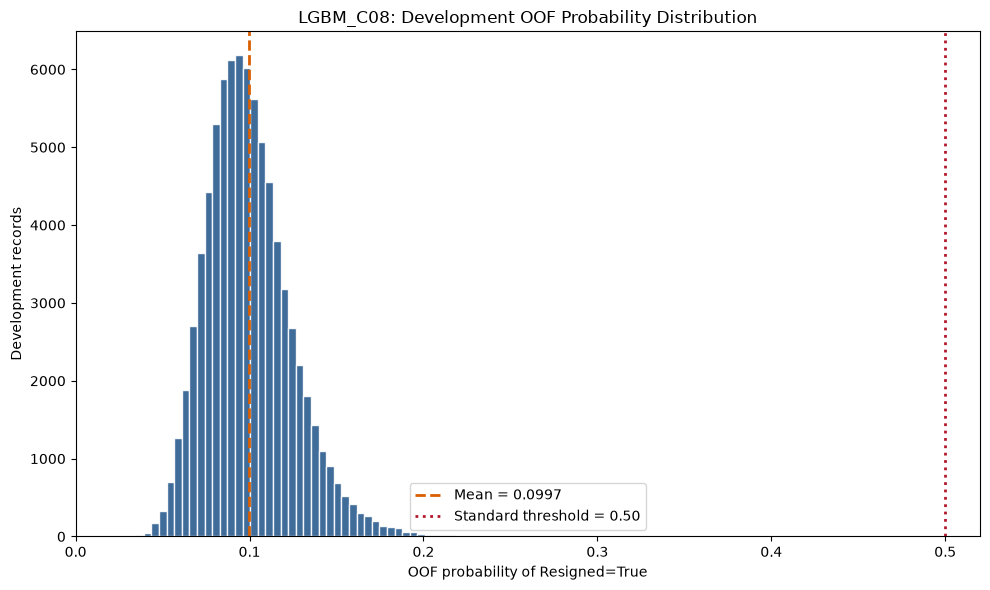

In [4]:
probabilities = final_oof['y_probability'].astype(float)
probability_statistics = pd.Series({
    'minimum': probabilities.min(),
    'maximum': probabilities.max(),
    'mean': probabilities.mean(),
    'median': probabilities.median(),
    'standard_deviation': probabilities.std(),
    'percentile_01': probabilities.quantile(0.01),
    'percentile_05': probabilities.quantile(0.05),
    'percentile_25': probabilities.quantile(0.25),
    'percentile_75': probabilities.quantile(0.75),
    'percentile_95': probabilities.quantile(0.95),
    'percentile_99': probabilities.quantile(0.99),
}, name='probability')
any_above_050 = bool((probabilities > 0.50).any())

print(f'Any selected OOF probability above 0.50: {any_above_050}')
display(probability_statistics.to_frame())

plt.figure(figsize=(10, 6))
plt.hist(probabilities, bins=60, color='#2b5c8f', edgecolor='white', alpha=0.9)
plt.axvline(probabilities.mean(), color='#d95f02', linestyle='--', linewidth=2, label=f'Mean = {probabilities.mean():.4f}')
plt.axvline(0.50, color='#b2182b', linestyle=':', linewidth=2, label='Standard threshold = 0.50')
plt.xlabel('OOF probability of Resigned=True')
plt.ylabel('Development records')
plt.title('LGBM_C08: Development OOF Probability Distribution')
plt.xlim(0.0, 0.52)
plt.legend()
plt.tight_layout()
plt.savefig(PROBABILITY_FIGURE, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

## 6. Historical C08 precision–recall curve

The selected candidate's saved development OOF probabilities are used directly. The horizontal reference equals development positive prevalence, representing no-skill expected precision.

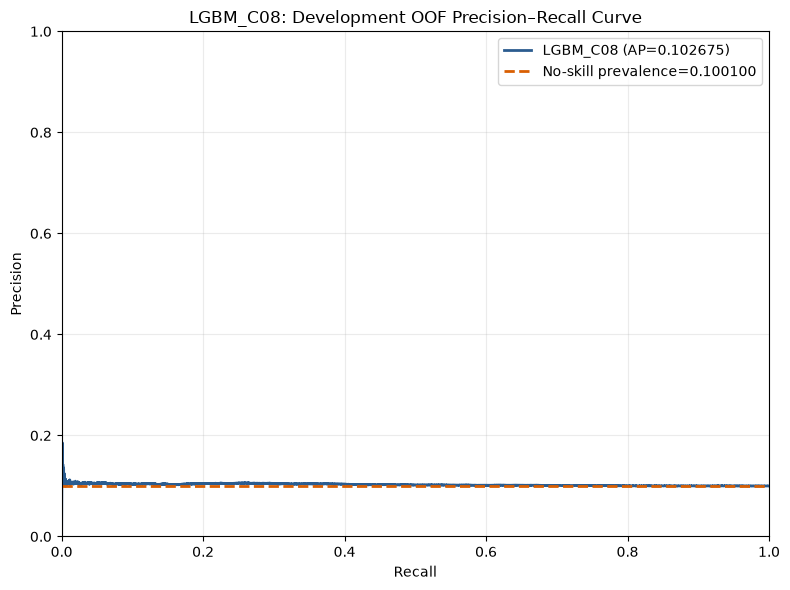

PR-AUC / Average Precision: 0.102675
No-skill prevalence: 0.100100


In [5]:
precision_curve, recall_curve, _ = precision_recall_curve(final_oof['y_true'], probabilities)
prevalence = float(final_oof['y_true'].mean())

plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, color='#2b5c8f', linewidth=2, label=f"LGBM_C08 (AP={standard_metrics['average_precision']:.6f})")
plt.axhline(prevalence, color='#d95f02', linestyle='--', linewidth=2, label=f'No-skill prevalence={prevalence:.6f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('LGBM_C08: Development OOF Precision–Recall Curve')
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.0)
plt.grid(alpha=0.25)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(PR_FIGURE, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print(f"PR-AUC / Average Precision: {standard_metrics['average_precision']:.6f}")
print(f'No-skill prevalence: {prevalence:.6f}')

## 7. Historical C08 threshold diagnostic

The existing development-only threshold analysis is retained without optimizing another threshold. Threshold 0.50 predicts no positives. The development F1-optimal threshold 0.04 predicts almost everyone positive, so threshold adjustment does not provide useful balanced discrimination. The 0.04 threshold is **not adopted** as an operational or final threshold.

In [6]:
selected_threshold = float(threshold_metadata['selected_threshold'])
selected_threshold_metrics = threshold_metadata['selected_threshold_metrics']
standard_threshold_metrics = threshold_metadata['standard_threshold_0_50_metrics']
assert selected_threshold == 0.04
assert standard_threshold_metrics['predicted_positive_count'] == 0
assert selected_threshold_metrics['predicted_positive_rate'] > 0.99
assert standard_metrics['predicted_positive_count'] == 0

threshold_report = pd.DataFrame([
    {'role': 'Standard reference', **standard_threshold_metrics},
    {'role': 'Development F1 diagnostic only', **selected_threshold_metrics},
])
display(threshold_report)
print('Operational/final threshold adopted from this diagnostic: NO')
print('Reason: 0.04 predicts almost everyone positive and balanced accuracy remains approximately 0.50.')

,role,threshold,precision,recall,f1,balanced_accuracy,predicted_positive_count,predicted_positive_rate
0,Standard reference,0.50,0.000000,0.00000,0.000000,0.500000,0.0,0.000000
1,Development F1 diagnostic only,0.04,0.100111,0.99975,0.181998,0.500063,79971.0,0.999637


Operational/final threshold adopted from this diagnostic: NO
Reason: 0.04 predicts almost everyone positive and balanced accuracy remains approximately 0.50.


## 8. Historical C01–C08 pooled candidate comparison

Eight YAML-bounded candidates were already evaluated on the same frozen folds. LGBM_C08 was selected by pooled OOF PR-AUC. Its improvement over fixed candidate LGBM_C01 is only 0.000122, so it is not described as meaningfully superior.

In [7]:
assert set(candidate_comparison['candidate_id']) == {f'LGBM_C{i:02d}' for i in range(1, 9)}
assert candidate_comparison.sort_values('pooled_average_precision', ascending=False).iloc[0]['candidate_id'] == 'LGBM_C08'
fixed_ap = float(candidate_comparison.loc[candidate_comparison['candidate_id'] == 'LGBM_C01', 'pooled_average_precision'].iloc[0])
selected_ap = float(final_summary['pooled_average_precision'])
assert np.isclose(selected_ap - fixed_ap, final_summary['difference_vs_fixed_baseline_pr_auc'])

display(candidate_comparison[[
    'candidate_id', 'rationale', 'pooled_average_precision', 'pooled_roc_auc',
    'pooled_brier_score', 'cv_mean_average_precision', 'cv_std_average_precision', 'wall_time_seconds'
]])
print(f'Selected improvement over fixed baseline: {selected_ap - fixed_ap:+.6f}')

,candidate_id,rationale,pooled_average_precision,pooled_roc_auc,pooled_brier_score,cv_mean_average_precision,cv_std_average_precision,wall_time_seconds
0,LGBM_C08,Strongest configured L1/L2 regularization,0.102675,0.507668,0.090567,0.103092,0.002469,26.313103
1,LGBM_C01,Committed fixed defaults,0.102553,0.506578,0.090692,0.103005,0.001097,13.738421
2,LGBM_C02,More boosting rounds,0.102443,0.505974,0.091292,0.102800,0.001808,35.774416
3,LGBM_C05,Higher leaf capacity,0.102174,0.503015,0.091177,0.102611,0.003066,28.615887
4,LGBM_C07,Full row and column fractions,0.101758,0.502542,0.090839,0.102283,0.002499,22.785904
5,LGBM_C06,Lower tree capacity,0.101608,0.505634,0.090501,0.102011,0.001490,18.670752
6,LGBM_C04,Higher learning rate with fewer rounds,0.100699,0.502149,0.090895,0.101099,0.002037,11.678551
7,LGBM_C03,Lower learning rate with more rounds,0.100663,0.500937,0.090316,0.101075,0.002570,32.706665


Selected improvement over fixed baseline: +0.000122


## 9. Historical selected-C08 feature importance

Gain and split-count importance were generated from a separate full-development interpretation fit after candidate selection. This fit was not used as performance evidence. Feature importance describes model splitting structure and does not imply causation.

,feature,importance_gain,importance_split
0,Department,3660.669104,1158
1,Employee_Satisfaction_Score,3598.242792,1338
2,Training_Hours,3069.054571,1171
3,Work_Hours_Per_Week,2624.349646,949
4,Age,2614.336766,960
5,Job_Title,2454.981719,788
6,Overtime_Hours,2453.637228,945
7,Projects_Handled,2441.330584,963
8,Monthly_Salary,2047.371197,734
9,Sick_Days,2029.714759,770


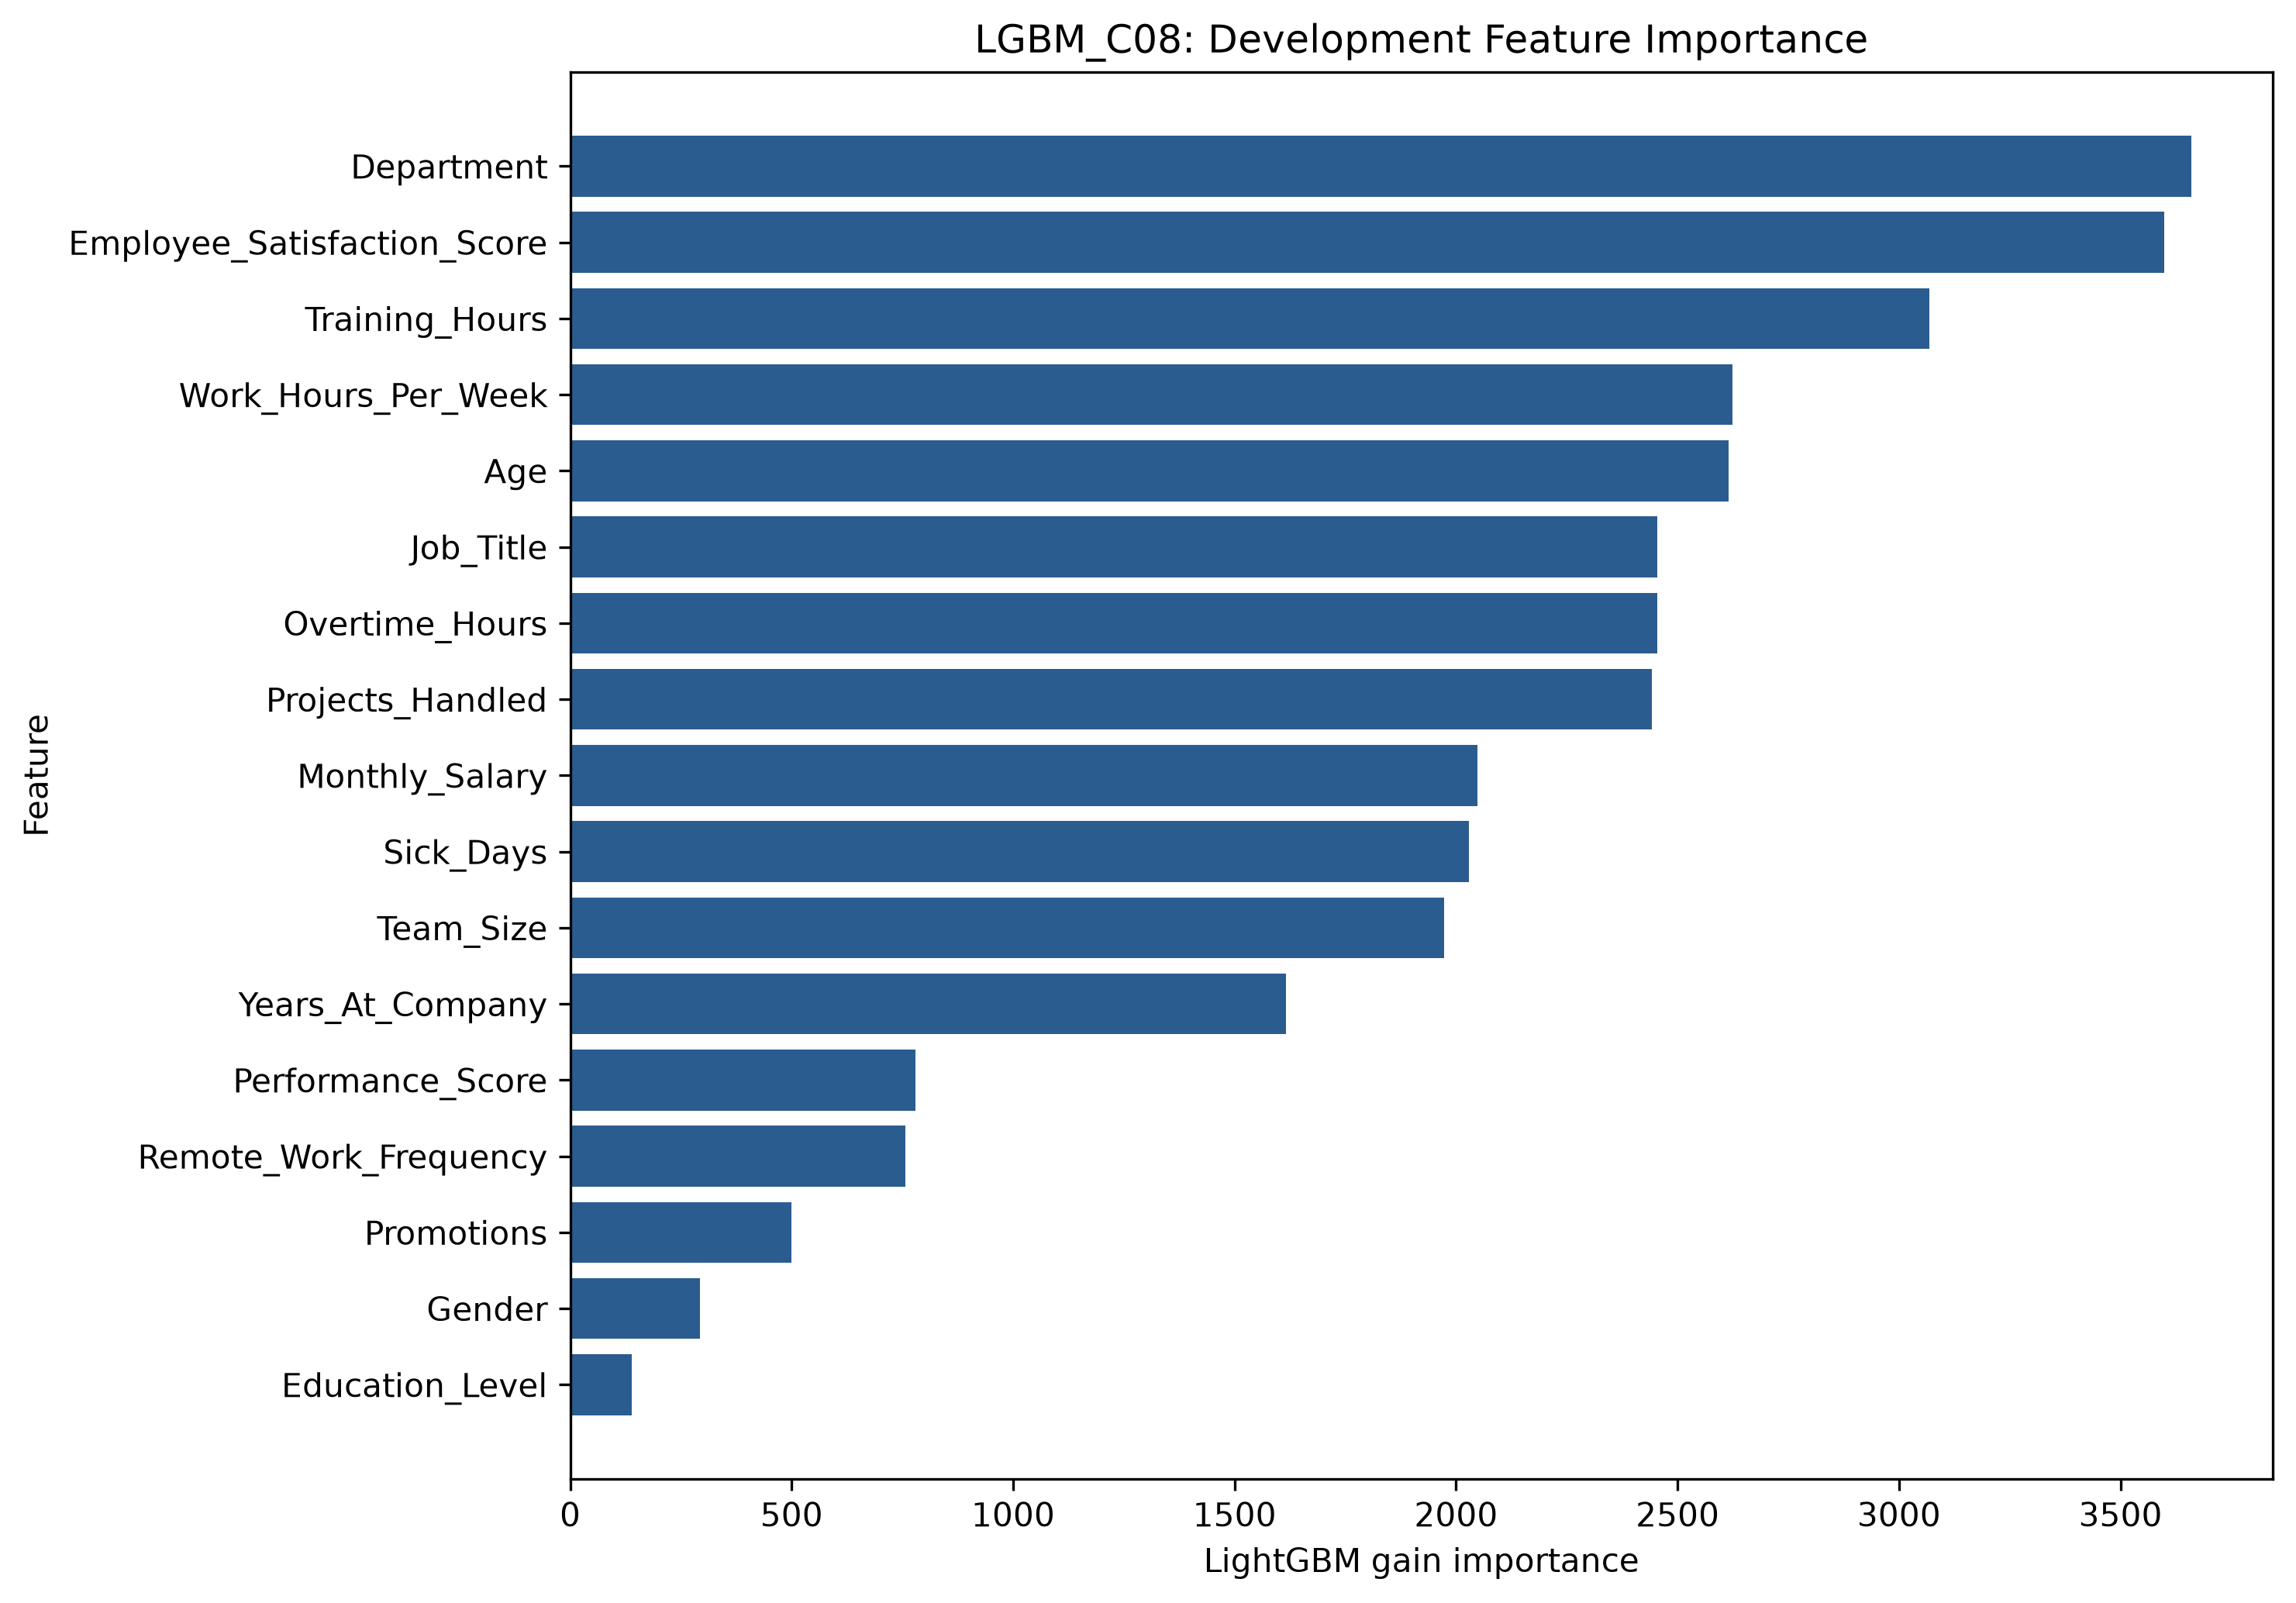

In [8]:
assert len(feature_importance) == 17
assert set(feature_importance.columns) == {'feature', 'importance_gain', 'importance_split'}
assert FINAL_IMPORTANCE_FIGURE.exists() and FINAL_IMPORTANCE_FIGURE.stat().st_size > 0
display(feature_importance)
display(Image(filename=str(FINAL_IMPORTANCE_FIGURE)))

## 10. Historical cross-model development context

The table below reads the already verified selected/principal development summaries for the completed headline models and the committed Dummy summary. PR-AUC is the primary comparison metric. No models are rerun.

In [9]:
cross_model_sources = {
    'LightGBM': RESULTS_DIR / 'lightgbm_final_summary_metrics.json',
    'XGBoost': PROJECT_ROOT / 'results' / 'models' / 'xgboost' / 'xgboost_summary_metrics.json',
    'TabNet': PROJECT_ROOT / 'results' / 'models' / 'tabnet' / 't01' / 'summary_metrics.json',
    'FT-Transformer': PROJECT_ROOT / 'results' / 'models' / 'ft_transformer' / 'weighted_early_stopping_final' / 'ft_transformer_final_summary_metrics.json',
    'EBM': PROJECT_ROOT / 'results' / 'models' / 'ebm' / 'ebm_summary_metrics.json',
}
cross_model_records = []
for model_name, summary_path in cross_model_sources.items():
    with summary_path.open('r', encoding='utf-8') as handle:
        model_summary = json.load(handle)
    cross_model_records.append({
        'model': model_name,
        'pooled_pr_auc': model_summary['pooled_average_precision'],
        'pooled_roc_auc': model_summary['pooled_roc_auc'],
    })

dummy_summary = pd.read_csv(PROJECT_ROOT / 'results' / 'baselines' / 'baseline_summary_metrics.csv')
for _, row in dummy_summary.iterrows():
    display_name = 'Dummy Most' if row['model_name'] == 'Dummy Most Frequent' else row['model_name']
    cross_model_records.append({'model': display_name, 'pooled_pr_auc': row['pr_auc'], 'pooled_roc_auc': row['roc_auc']})

cross_model_comparison = pd.DataFrame(cross_model_records).sort_values('pooled_pr_auc', ascending=False).reset_index(drop=True)
display(cross_model_comparison)

xgboost_ap = float(cross_model_comparison.loc[cross_model_comparison['model'] == 'XGBoost', 'pooled_pr_auc'].iloc[0])
dummy_prior_ap = float(cross_model_comparison.loc[cross_model_comparison['model'] == 'Dummy Prior', 'pooled_pr_auc'].iloc[0])
dummy_most_ap = float(cross_model_comparison.loc[cross_model_comparison['model'] == 'Dummy Most', 'pooled_pr_auc'].iloc[0])
assert np.isclose(selected_ap - xgboost_ap, 0.00004669842849579024)

print(f'LightGBM advantage over XGBoost: {selected_ap - xgboost_ap:+.6f}')
print(f'LightGBM advantage over Dummy Prior: {selected_ap - dummy_prior_ap:+.6f}')
print(f'LightGBM advantage over Dummy Most: {selected_ap - dummy_most_ap:+.6f}')

,model,pooled_pr_auc,pooled_roc_auc
0,LightGBM,0.102675,0.507668
1,XGBoost,0.102628,0.506130
2,TabNet,0.101706,0.504556
3,Dummy Most,0.100100,0.500000
4,Dummy Prior,0.100085,0.499917
5,FT-Transformer,0.099979,0.497254
6,EBM,0.098543,0.493466


LightGBM advantage over XGBoost: +0.000047
LightGBM advantage over Dummy Prior: +0.002590
LightGBM advantage over Dummy Most: +0.002575


## 11. Limitations

- The supplied Resigned target appears weakly predictable from the approved feature set: completed model-family PR-AUC values remain close to the approximately 0.1001 no-skill level, and ROC-AUC values remain close to 0.50.
- Extensive additional parameter search is unlikely to be justified by the observed evidence.
- Accuracy near 90% is misleading because approximately 90% of employees are in the negative class.
- Feature importance describes model behavior and does not imply causation.
- Threshold changes cannot create ranking information absent from the probability scores.
- Class weighting was not introduced because it is outside the current LightGBM contract and would not guarantee improved PR-AUC.
- The development-selected threshold 0.04 is diagnostic only and is not adopted.
- The formal holdout remains untouched; no production-usefulness claim is made.

## 12. Output verification

All fixed-baseline, bounded-candidate, selected-model, diagnostic, feature-importance, and metadata artifacts are checked for existence and non-zero size. Candidate OOF outputs are also checked for complete development-ID coverage and holdout isolation.

In [10]:
required_artifacts = [
    RESULTS_DIR / 'oof_predictions.csv',
    RESULTS_DIR / 'fold_metrics.csv',
    RESULTS_DIR / 'summary_metrics.json',
    RESULTS_DIR / 'feature_importances.csv',
    RESULTS_DIR / 'figure_01_lightgbm_feature_importance.png',
    RESULTS_DIR / 'lightgbm_run_metadata.json',
    CANDIDATE_COMPARISON_PATH,
    SELECTED_CONFIG_PATH,
    FINAL_OOF_PATH,
    FINAL_FOLD_PATH,
    FINAL_SUMMARY_PATH,
    THRESHOLD_PATH,
    THRESHOLD_METADATA_PATH,
    FINAL_IMPORTANCE_PATH,
    FINAL_IMPORTANCE_FIGURE,
    PROBABILITY_FIGURE,
    PR_FIGURE,
    RESULTS_DIR / 'lightgbm_selected_run_metadata.json',
]
assert all(path.exists() and path.stat().st_size > 0 for path in required_artifacts)

for candidate_id in (f'LGBM_C{i:02d}' for i in range(1, 9)):
    candidate_dir = RESULTS_DIR / 'tuning' / candidate_id
    candidate_oof_path = candidate_dir / 'oof_predictions.csv'
    candidate_fold_path = candidate_dir / 'fold_metrics.csv'
    candidate_summary_path = candidate_dir / 'summary_metrics.json'
    candidate_params_path = candidate_dir / 'parameters.json'
    assert all(path.exists() and path.stat().st_size > 0 for path in [candidate_oof_path, candidate_fold_path, candidate_summary_path, candidate_params_path])
    candidate_oof = pd.read_csv(candidate_oof_path, usecols=[id_col, 'cv_fold', 'y_probability'])
    assert len(candidate_oof) == 80_000 and candidate_oof[id_col].nunique() == 80_000
    assert set(candidate_oof[id_col]) == set(dev_registry[id_col])
    assert set(candidate_oof[id_col]).isdisjoint(set(holdout_registry[id_col]))
    assert candidate_oof['y_probability'].between(0.0, 1.0).all()

assert not any('holdout' in path.name.lower() for path in RESULTS_DIR.rglob('*') if path.is_file())
print(f'Important non-empty artifacts verified: {len(required_artifacts)}')
print('Eight candidate OOF outputs: 80,000 unique development IDs each; no holdout IDs')
print('Final selected OOF: 80,000 rows, 80,000 unique IDs; no holdout IDs')

Important non-empty artifacts verified: 18
Eight candidate OOF outputs: 80,000 unique development IDs each; no holdout IDs
Final selected OOF: 80,000 rows, 80,000 unique IDs; no holdout IDs


## 13. Historical Member 4 conclusion

The final statement is generated from validated saved outputs so that its values remain consistent with the notebook tables.

In [11]:
final_conclusion = f'''### Historical pre-harmonization LightGBM conclusion

- **Model:** LightGBM
- **Selected configuration:** {selected_config['candidate_id']}
- **Development records:** {len(final_oof):,}
- **Frozen folds:** {len(set(final_oof['cv_fold']))}
- **Primary PR-AUC:** {standard_metrics['average_precision']:.6f}
- **ROC-AUC:** {standard_metrics['roc_auc']:.6f}
- **Brier score:** {standard_metrics['brier_score']:.6f}
- **Threshold 0.50:** predicts {standard_metrics['predicted_positive_count']:,} positives; precision={standard_metrics['precision']:.6f}, recall={standard_metrics['recall']:.6f}, F1={standard_metrics['f1']:.6f}
- **Development F1 threshold diagnostic:** 0.04 predicts {int(selected_threshold_metrics['predicted_positive_count']):,} positives ({selected_threshold_metrics['predicted_positive_rate']:.4%}) and is not adopted
- **Difference versus fixed baseline PR-AUC:** {selected_ap - fixed_ap:+.6f}
- **Difference versus Dummy Prior / Dummy Most:** {selected_ap - dummy_prior_ap:+.6f} / {selected_ap - dummy_most_ap:+.6f}
- **Difference versus XGBoost:** {selected_ap - xgboost_ap:+.6f}
- **OOF validation:** passed for all 80,000 development records
- **Tuning scope:** completed eight bounded candidates; no further tuning performed here
- **Formal holdout:** not used

The LightGBM implementation is technically valid and achieved the highest recorded development PR-AUC among the currently completed headline models, but its improvement over no-skill baselines is very small. Together with similar results across substantially different model families, this provides evidence that the approved feature set contains limited stable predictive signal for the supplied Resigned label. This experiment does not establish production usefulness.
'''
display(Markdown(final_conclusion))

### Final LightGBM development conclusion

- **Model:** LightGBM
- **Selected configuration:** LGBM_C08
- **Development records:** 80,000
- **Frozen folds:** 5
- **Primary PR-AUC:** 0.102675
- **ROC-AUC:** 0.507668
- **Brier score:** 0.090567
- **Threshold 0.50:** predicts 0 positives; precision=0.000000, recall=0.000000, F1=0.000000
- **Development F1 threshold diagnostic:** 0.04 predicts 79,971 positives (99.9637%) and is not adopted
- **Difference versus fixed baseline PR-AUC:** +0.000122
- **Difference versus Dummy Prior / Dummy Most:** +0.002590 / +0.002575
- **Difference versus XGBoost:** +0.000047
- **OOF validation:** passed for all 80,000 development records
- **Tuning scope:** completed eight bounded candidates; no further tuning performed here
- **Formal holdout:** not used

The LightGBM implementation is technically valid and achieved the highest recorded development PR-AUC among the currently completed headline models, but its improvement over no-skill baselines is very small. Together with similar results across substantially different model families, this provides evidence that the approved feature set contains limited stable predictive signal for the supplied Resigned label. This experiment does not establish production usefulness.
